# EDA básico: Resultados únicos Saber 11

**Autores:** Erlyn Martinez y Jonatan Esguerra

## 1. Carga y configuración

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)

AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#8a8985'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c9c8c3', 'axes.grid': True, 'grid.color': '#e8e7e2',
    'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'figure.dpi': 100
})

df = pd.read_csv('../data/raw/saber11.csv', encoding='utf-8-sig', low_memory=False)
df.shape

(36613, 51)

## 2. Estructura general

* filas: 36.613
* columnas: 51

In [2]:
df.dtypes.value_counts()

str        35
float64     9
int64       7
Name: count, dtype: int64

In [3]:
df.head(3).T

,0,1,2
PERIODO,20132,20162,20172
ESTU_TIPODOCUMENTO,TI,CC,TI
ESTU_CONSECUTIVO,SB11201320260952,SB11201620253914,SB11201720214776
COLE_AREA_UBICACION,URBANO,URBANO,URBANO
COLE_BILINGUE,N,N,N
COLE_CALENDARIO,A,A,A
COLE_CARACTER,TÉCNICO/ACADÉMICO,TÉCNICO/ACADÉMICO,TÉCNICO/ACADÉMICO
COLE_COD_DANE_ESTABLECIMIENTO,115491000017,115759001887,115759000473
COLE_COD_DANE_SEDE,115491000017,115759001887,115759000473
COLE_COD_DEPTO_UBICACION,15,15,15


## 3. Valores nulos

In [4]:
nulos = df.isna().sum()
resumen_nulos = pd.DataFrame({'nulos': nulos, 'porcentaje': (nulos / len(df) * 100).round(2)})
resumen_nulos[resumen_nulos.nulos > 0].sort_values('porcentaje', ascending=False)

,nulos,porcentaje
PUNT_GLOBAL,13139,35.89
PUNT_LECTURA_CRITICA,13139,35.89
PUNT_C_NATURALES,13139,35.89
PUNT_SOCIALES_CIUDADANAS,13139,35.89
COLE_BILINGUE,1534,4.19
FAMI_EDUCACIONMADRE,1361,3.72
FAMI_EDUCACIONPADRE,1353,3.70
FAMI_ESTRATOVIVIENDA,1020,2.79
FAMI_TIENECOMPUTADOR,967,2.64
FAMI_TIENEINTERNET,891,2.43


* nulos en sociales, naturales, lectura y global: 13.139 (35,9 %)
* causa: periodos anteriores a 2014-2
* nulos en variables familiares: menos de 4 %

In [5]:
nulos_periodo = df.groupby('PERIODO')['PUNT_GLOBAL'].apply(lambda s: s.isna().mean() * 100).round(1)
nulos_periodo

PERIODO
20101    100.0
20102    100.0
20111    100.0
20112    100.0
20121    100.0
20122    100.0
20131    100.0
20132    100.0
20141    100.0
20142      0.0
20151      0.0
20152      0.0
20162      0.0
20172      0.0
20181      0.0
20194      0.0
20201      0.0
20211      0.0
20221      0.0
20224      0.0
Name: PUNT_GLOBAL, dtype: float64

## 4. Duplicados

In [6]:
print('Filas duplicadas exactas:', df.duplicated().sum())
print('Identificadores repetidos:', df['ESTU_CONSECUTIVO'].duplicated().sum())
df[df.duplicated()].groupby('PERIODO').size()

Filas duplicadas exactas: 5759
Identificadores repetidos: 5759


PERIODO
20194    2929
20224    2830
dtype: int64

* valores repetidos: 5.759 (filas idénticas)
* periodos: 2019-4 y 2022-4
* filas después de eliminarlos: 30.854

In [7]:
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(30854, 51)

## 5. Estudiantes por periodo

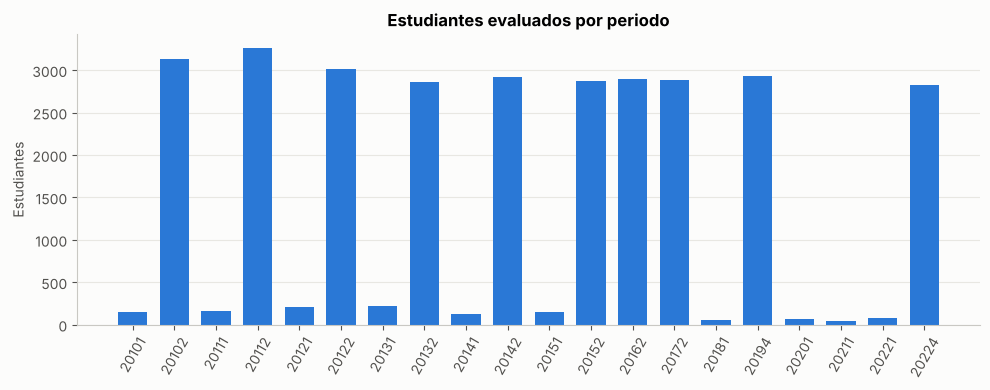

In [8]:
por_periodo = df['PERIODO'].astype(str).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(por_periodo.index, por_periodo.values, color=AZUL, width=0.7)
ax.set_title('Estudiantes evaluados por periodo')
ax.set_ylabel('Estudiantes')
ax.tick_params(axis='x', rotation=60)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

* periodos: 20
* periodos grandes (2 o 4): 2.800 a 3.300 estudiantes
* periodos pequeños (1): menos de 220

## 6. Estadísticos descriptivos de los puntajes

In [9]:
puntajes = ['PUNT_INGLES', 'PUNT_MATEMATICAS', 'PUNT_SOCIALES_CIUDADANAS', 'PUNT_C_NATURALES', 'PUNT_LECTURA_CRITICA', 'PUNT_GLOBAL']
df[puntajes].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
PUNT_INGLES,30854.0,50.17,10.51,-1.0,43.0,49.0,56.0,117.29
PUNT_MATEMATICAS,30854.0,52.42,11.32,0.0,45.0,52.0,60.0,101.00
PUNT_SOCIALES_CIUDADANAS,17715.0,52.77,10.57,0.0,45.0,53.0,60.0,100.00
PUNT_C_NATURALES,17715.0,54.07,9.26,0.0,48.0,54.0,60.0,100.00
PUNT_LECTURA_CRITICA,17715.0,54.41,9.37,0.0,48.0,54.0,61.0,100.00
PUNT_GLOBAL,17715.0,269.81,43.96,0.0,238.0,269.0,300.0,449.00


* PUNT_INGLES negativos: 13
* PUNT_INGLES mayores a 100: 5

In [10]:
df.loc[(df.PUNT_INGLES < 0) | (df.PUNT_INGLES > 100), ['PERIODO', 'PUNT_INGLES']].sort_values('PUNT_INGLES')

,PERIODO,PUNT_INGLES
3617,20122,-1.00
3714,20132,-1.00
3912,20132,-1.00
4155,20112,-1.00
4249,20132,-1.00
6006,20112,-1.00
9059,20132,-1.00
15879,20102,-1.00
24133,20112,-1.00
19824,20122,-1.00


## 7. Distribución de los puntajes

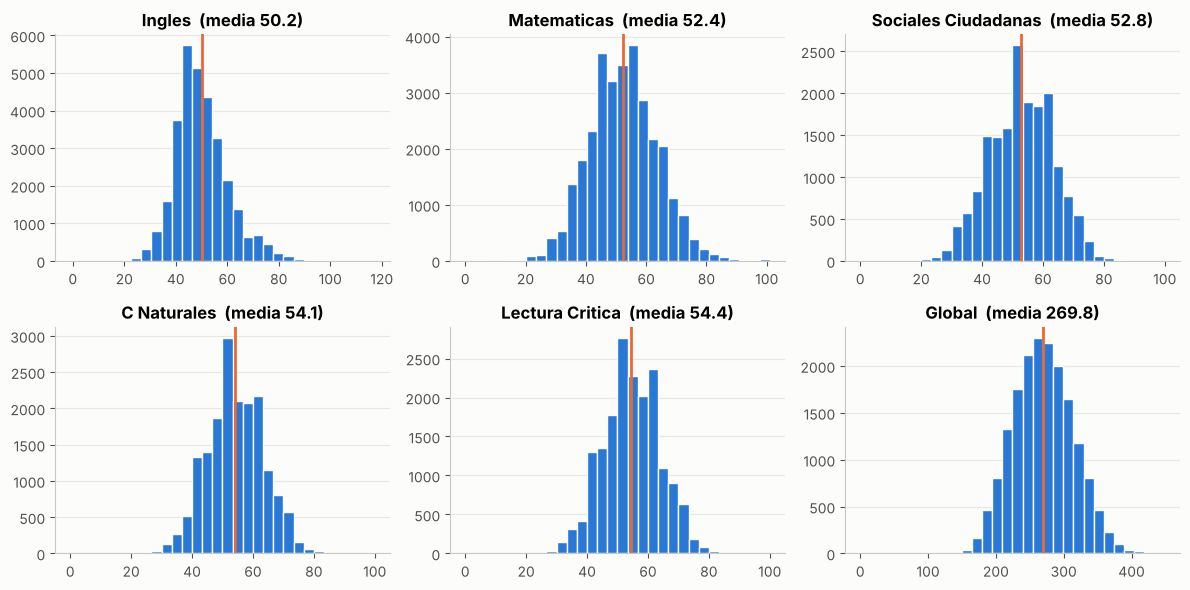

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), puntajes):
    datos = df[col].dropna()
    ax.hist(datos, bins=30, color=AZUL, edgecolor='#fcfcfb', linewidth=1)
    ax.axvline(datos.mean(), color=NARANJA, linewidth=2)
    ax.set_title(col.replace('PUNT_', '').replace('_', ' ').title() + f'  (media {datos.mean():.1f})')
    ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

* media sociales: 52,8
* media naturales: 54,1
* media lectura: 54,4
* media matemáticas: 52,4
* media inglés: 50,2
* media global: 269,8

## 8. Correlación entre pruebas

Solo se usan los periodos desde 2014-2, que son los que tienen puntaje global.

In [12]:
reciente = df[df['PUNT_GLOBAL'].notna()]
corr = reciente[puntajes].corr().round(2)
corr

,PUNT_INGLES,PUNT_MATEMATICAS,PUNT_SOCIALES_CIUDADANAS,PUNT_C_NATURALES,PUNT_LECTURA_CRITICA,PUNT_GLOBAL
PUNT_INGLES,1.00,0.61,0.63,0.64,0.63,0.75
PUNT_MATEMATICAS,0.61,1.00,0.69,0.76,0.69,0.89
PUNT_SOCIALES_CIUDADANAS,0.63,0.69,1.00,0.75,0.74,0.89
PUNT_C_NATURALES,0.64,0.76,0.75,1.00,0.70,0.90
PUNT_LECTURA_CRITICA,0.63,0.69,0.74,0.70,1.00,0.87
PUNT_GLOBAL,0.75,0.89,0.89,0.90,0.87,1.00


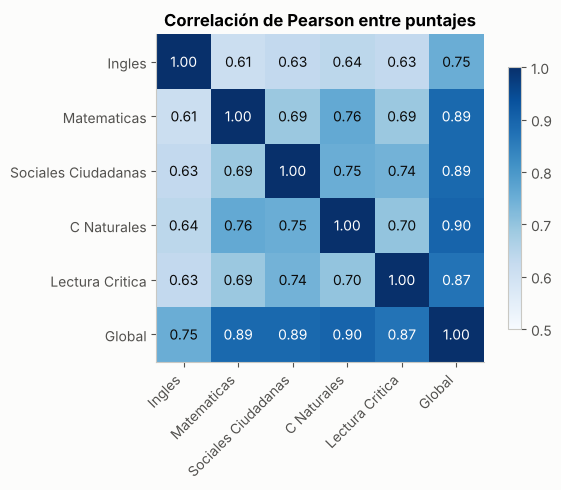

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr.values, cmap='Blues', vmin=0.5, vmax=1)
etiquetas = [c.replace('PUNT_', '').replace('_', ' ').title() for c in puntajes]
ax.set_xticks(range(6)); ax.set_xticklabels(etiquetas, rotation=45, ha='right')
ax.set_yticks(range(6)); ax.set_yticklabels(etiquetas)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center',
                color='white' if corr.values[i, j] > 0.8 else '#0b0b0b')
ax.grid(False)
ax.set_title('Correlación de Pearson entre puntajes')
plt.colorbar(im, shrink=0.8)
plt.tight_layout()
plt.show()

* correlación con puntaje global: 0,75 a 0,90
* correlación entre áreas: cerca de 0,7 o más

## 9. Variables categóricas del colegio y del estudiante

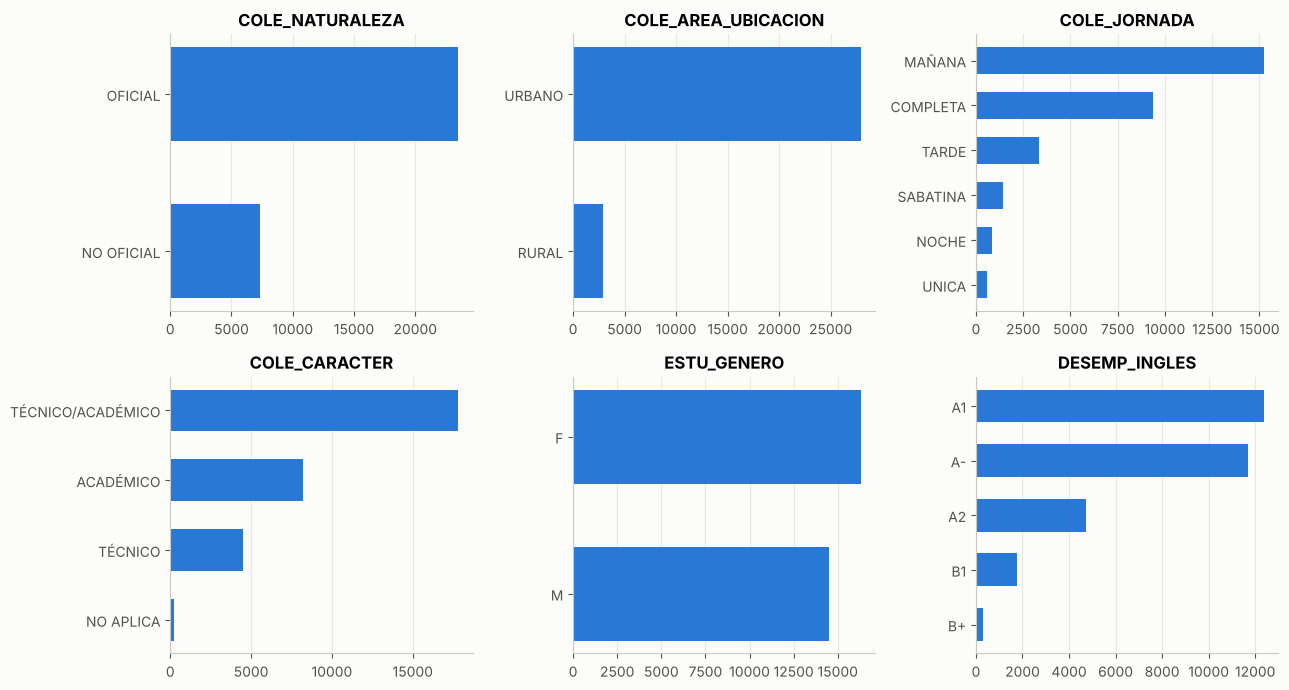

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
cols = ['COLE_NATURALEZA', 'COLE_AREA_UBICACION', 'COLE_JORNADA', 'COLE_CARACTER', 'ESTU_GENERO', 'DESEMP_INGLES']
for ax, col in zip(axes.ravel(), cols):
    vc = df[col].value_counts().sort_values()
    ax.barh(vc.index.astype(str), vc.values, color=AZUL, height=0.6)
    ax.set_title(col)
    ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

* colegios oficiales: 76 %
* colegios urbanos: 91 %
* jornada mañana: 49 %
* inglés A- y A1: 78 %

In [15]:
df['ESTU_GENERO'].value_counts(normalize=True).round(3)

ESTU_GENERO
F    0.53
M    0.47
Name: proportion, dtype: float64

## 10. Entorno familiar

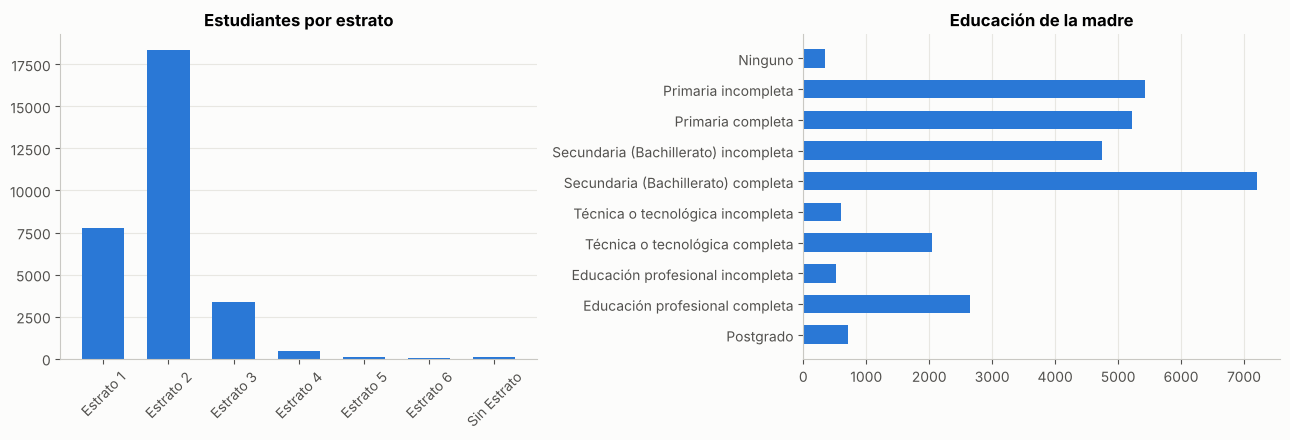

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
estrato = df['FAMI_ESTRATOVIVIENDA'].value_counts().reindex(['Estrato 1', 'Estrato 2', 'Estrato 3', 'Estrato 4', 'Estrato 5', 'Estrato 6', 'Sin Estrato'])
axes[0].bar(estrato.index, estrato.values, color=AZUL, width=0.65)
axes[0].set_title('Estudiantes por estrato')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='x', visible=False)
orden_edu = ['Ninguno', 'Primaria incompleta', 'Primaria completa', 'Secundaria (Bachillerato) incompleta', 'Secundaria (Bachillerato) completa', 'Técnica o tecnológica incompleta', 'Técnica o tecnológica completa', 'Educación profesional incompleta', 'Educación profesional completa', 'Postgrado']
edu = df['FAMI_EDUCACIONMADRE'].value_counts().reindex(orden_edu)
axes[1].barh(edu.index[::-1], edu.values[::-1], color=AZUL, height=0.6)
axes[1].set_title('Educación de la madre')
axes[1].grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

* estratos 1 y 2: más de 85 %
* educación de la madre más frecuente: bachillerato completo

In [17]:
df[['FAMI_TIENECOMPUTADOR', 'FAMI_TIENEINTERNET', 'FAMI_TIENEAUTOMOVIL', 'FAMI_TIENELAVADORA']].apply(lambda s: s.value_counts(normalize=True)).round(3)

,FAMI_TIENECOMPUTADOR,FAMI_TIENEINTERNET,FAMI_TIENEAUTOMOVIL,FAMI_TIENELAVADORA
No,0.421,0.593,0.708,0.393
Si,0.579,0.407,0.292,0.607


## 11. Puntaje global frente a variables explicativas

Se usa el subconjunto con puntaje global (desde 2014-2).

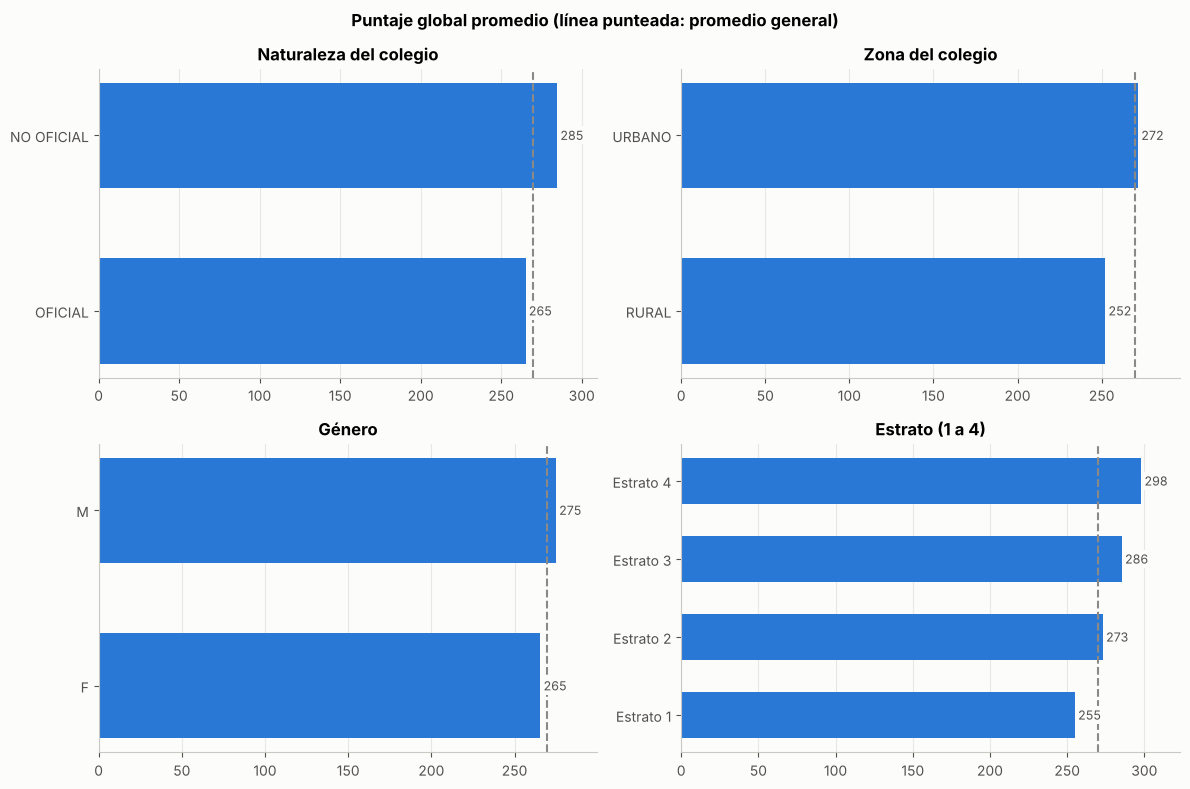

In [18]:
def barras_media(ax, serie, titulo, color=AZUL):
    m = serie.sort_values()
    ax.barh(m.index.astype(str), m.values, color=color, height=0.6)
    ax.axvline(reciente['PUNT_GLOBAL'].mean(), color=GRIS, linewidth=1.5, linestyle='--')
    ax.set_title(titulo)
    ax.set_xlim(0, m.max() + 25)
    ax.grid(axis='y', visible=False)
    for y, v in enumerate(m.values):
        ax.text(v + 2, y, f'{v:.0f}', va='center', fontsize=9, color='#52514e', bbox=dict(facecolor='#fcfcfb', edgecolor='none', pad=1))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
barras_media(axes[0, 0], reciente.groupby('COLE_NATURALEZA')['PUNT_GLOBAL'].mean(), 'Naturaleza del colegio')
barras_media(axes[0, 1], reciente.groupby('COLE_AREA_UBICACION')['PUNT_GLOBAL'].mean(), 'Zona del colegio')
barras_media(axes[1, 0], reciente.groupby('ESTU_GENERO')['PUNT_GLOBAL'].mean(), 'Género')
est = reciente[reciente.FAMI_ESTRATOVIVIENDA.isin(['Estrato 1', 'Estrato 2', 'Estrato 3', 'Estrato 4'])]
barras_media(axes[1, 1], est.groupby('FAMI_ESTRATOVIVIENDA')['PUNT_GLOBAL'].mean(), 'Estrato (1 a 4)')
plt.suptitle('Puntaje global promedio (línea punteada: promedio general)', fontweight='bold')
plt.tight_layout()
plt.show()

* no oficial vs oficial: 285 vs 265
* urbano vs rural: 272 vs 252
* hombres vs mujeres: 275 vs 265
* estrato 1 a 4: 255, 273, 286, 298

## 12. Puntaje global por municipio y por periodo

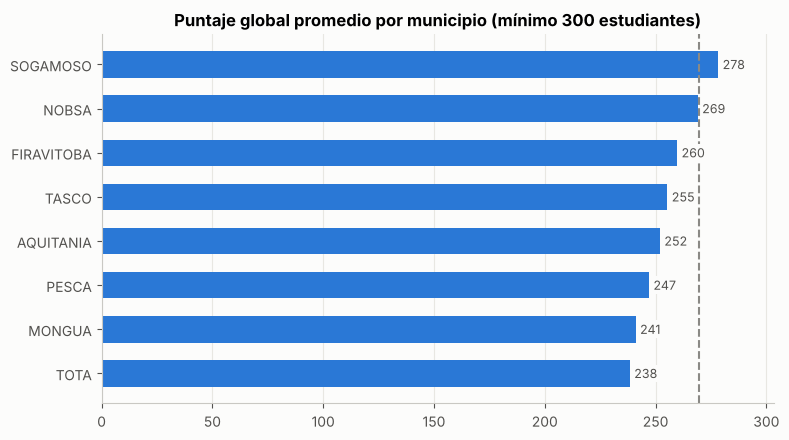

In [19]:
mun = reciente.groupby('COLE_MCPIO_UBICACION')['PUNT_GLOBAL'].agg(['count', 'mean'])
mun = mun[mun['count'] >= 300].sort_values('mean')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(mun.index, mun['mean'], color=AZUL, height=0.6)
ax.axvline(reciente['PUNT_GLOBAL'].mean(), color=GRIS, linewidth=1.5, linestyle='--')
ax.set_xlim(0, mun['mean'].max() + 25)
ax.set_title('Puntaje global promedio por municipio (mínimo 300 estudiantes)')
ax.grid(axis='y', visible=False)
for y, v in enumerate(mun['mean']):
    ax.text(v + 2, y, f'{v:.0f}', va='center', fontsize=9, color='#52514e', bbox=dict(facecolor='#fcfcfb', edgecolor='none', pad=1))
plt.tight_layout()
plt.show()

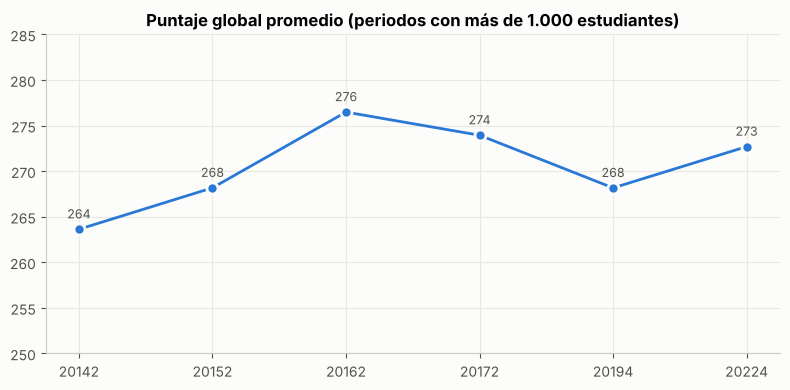

In [20]:
grandes = reciente.groupby('PERIODO')['PUNT_GLOBAL'].agg(['count', 'mean'])
grandes = grandes[grandes['count'] > 1000]
fig, ax = plt.subplots(figsize=(8, 4))
x = grandes.index.astype(str)
ax.plot(x, grandes['mean'], color=AZUL, linewidth=2, marker='o', markersize=8, markeredgecolor='#fcfcfb', markeredgewidth=2)
for xi, v in zip(x, grandes['mean']):
    ax.text(xi, v + 1.2, f'{v:.0f}', ha='center', fontsize=9, color='#52514e')
ax.set_ylim(250, 285)
ax.set_title('Puntaje global promedio (periodos con más de 1.000 estudiantes)')
plt.tight_layout()
plt.show()

* municipio más alto: Sogamoso (278)
* municipios más bajos: Tota (238) y Mongua (241)
* media por periodo (periodos grandes): 263 a 277

## 13. Resumen

* nulos: 13.139 en puntaje global y áreas (periodos antes de 2014-2)
* valores repetidos: 5.759
* estudiantes finales: 30.854
* valores fuera de rango en inglés: 18
* columnas constantes: departamento, municipio de presentación y calendario